# 02 — From coin to quantum sensor

**Draft tutorial · 14 September 2026.** Read [notebook 01](../tutorials/01_when_the_coin_has_memory.ipynb)
first. This notebook connects its coin with memory to a quantum measurement, then compares two
readout settings at the project's two parameter sets.

A Ramsey measurement prepares a superposition, lets it accumulate phase, and converts that phase
into a binary outcome. Call one outcome $Y=1$. Conditional on the hidden phase $\epsilon$, it is
still a coin toss:

$$P(Y=1\mid\epsilon)=\frac{1+C\cos(\theta+\epsilon)}{2}.$$

Here $\theta$ is the chosen readout angle and $C$ is the effective contrast **at that interrogation
time**. The calculation uses the same link as the research simulator. All figures below are live,
deterministic teaching calculations; none adds evidence to the ledger.

By the end you should be able to explain what changes at an extremum and at mid-fringe, read a
crossover plot without mistaking it for a measured delay, and say which clock costs still need
calibration.


In [1]:
import math, os, sys, io
from pathlib import Path

import numpy as np
from scipy.optimize import brentq
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

# Import the project's tested functions rather than restating the formulas here.
# Normally the notebook is opened from tutorials/, so walking up finds the repository.
# SID_ROOT overrides that, which is how the test executes it from a temporary directory.
ROOT = Path(os.environ["SID_ROOT"]) if os.environ.get("SID_ROOT") else Path.cwd()
while not (ROOT / "analysis" / "lib").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "analysis" / "lib").is_dir():
    raise RuntimeError("run this notebook from inside the repository, or set SID_ROOT")
sys.path.insert(0, str(ROOT / "analysis" / "lib"))
from sid_lib import (DB, ramsey_probability, ramsey_mean, rk_exact, I_ext_exact,
                     I_mid_gp, INK, SEA, SIG, STONE, PARCH)

plt.rcParams.update({"font.family": "serif", "figure.dpi": 130,
                     "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.5})


# sid_lib selects the Agg backend on import, disabling the inline formatter, so figures are
# rendered explicitly. IPython is optional: without it the notebook still runs top to bottom
# (that is how the test executes it), it simply draws nothing.
try:
    from IPython.display import Image, display
    _INLINE = True
except ImportError:
    _INLINE = False

def show(fig):
    if _INLINE:
        buf = io.BytesIO(); fig.savefig(buf, format="png", bbox_inches="tight")
        display(Image(data=buf.getvalue()))
    plt.close(fig)

# Lines prefixed [env] record which stack executed the notebook. They are provenance, not
# results, and are excluded when the tests compare fresh output against committed output --
# they are *expected* to differ between interpreters.
print("[env] project root:", ROOT.name)
import scipy
print("[env] python", ".".join(map(str, sys.version_info[:3])), "| numpy", np.__version__,
      "| scipy", scipy.__version__, "| matplotlib", matplotlib.__version__)


[env] project root: signals-in-darkness
[env] python 3.13.7 | numpy 2.4.4 | scipy 1.17.1 | matplotlib 3.10.8


## 1. The control knob changes which clue is visible

The fringe's depth is set by $C$. At the dark extremum, $\theta=\pi$, the probability of $Y=1$ is
smallest. At mid-fringe, $\theta=\pi/2$, it is one half. Neither setting makes the outcome certain
at the contrasts used here.

A zero-mean Gaussian phase with standard deviation $s$ lowers the average fringe contrast by
$e^{-s^2/2}$. It lifts the dark minimum, but leaves the mid-fringe average at one half. The shaded
change below is an average over phase, not a claim that the individual shots are independent.

| symbol | meaning here |
|---|---|
| $C$ | effective contrast at a fixed interrogation time; called $C_{\rm eff}$ or $\bar C$ in the record |
| $s$ | standard deviation of the sampled hidden phase, in radians |
| $c=\tau+t_{\rm dead}$ | cycle time: interrogation plus preparation/readout |
| $\tau_c/c$ | how many cycles fit in the signal's correlation time |

In the fully randomised two-clock parity readout, $C_{\rm eff}=C_1C_2/2\leq 0.5$.
The pilot $(C,s)=(0.4,0.5)$ is inside this regime. The stress point $(0.5,0.3)$ sits
**at the parity ceiling**: it is an upper-bound stress test, not a realistic contrast assumption.
This ceiling belongs to that parity model, not to every quantum sensor. The $C_0$ in notebook 03 will instead
mean contrast **before** interrogation-time decay.


mid-fringe    : P(Y=1) before 0.500000, after 0.500000, change +0.000000
dark extremum : P(Y=1) before 0.300000, after 0.323501, change +0.023501


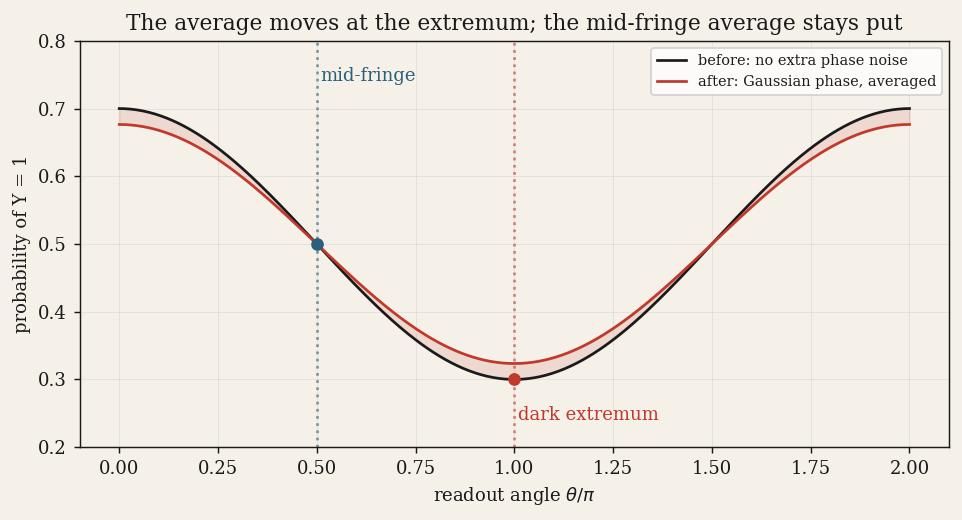

In [2]:
PILOT = (0.4, 0.5)
STRESS = (0.5, 0.3)
C, s = PILOT
angles = np.linspace(0, 2*np.pi, 401)
p_before = ramsey_probability(C, angles)
p_after = ramsey_mean(C, s, angles)
fig, ax = plt.subplots(figsize=(7.5, 4.1), facecolor=PARCH)
ax.set_facecolor(PARCH)
ax.plot(angles/np.pi, p_before, color=INK, label="before: no extra phase noise")
ax.plot(angles/np.pi, p_after, color=SIG, label="after: Gaussian phase, averaged")
ax.fill_between(angles/np.pi, p_before, p_after, color=SIG, alpha=0.12)
for theta, label, color in [(np.pi/2, "mid-fringe", SEA), (np.pi, "dark extremum", SIG)]:
    p0 = ramsey_probability(C, theta)
    p1 = ramsey_mean(C, s, theta)
    ax.scatter([theta/np.pi], [p0], color=color, zorder=4)
    ax.axvline(theta/np.pi, color=color, ls=":", alpha=0.6)
    print(f"{label:14s}: P(Y=1) before {p0:.6f}, after {p1:.6f}, change {p1-p0:+.6f}")
ax.text(0.51, 0.74, "mid-fringe", color=SEA)
ax.text(1.01, 0.24, "dark extremum", color=SIG)
ax.set(xlabel=r"readout angle $\theta/\pi$", ylabel="probability of Y = 1",
       ylim=(0.2, 0.8), title="The average moves at the extremum; the mid-fringe average stays put")
ax.legend(fontsize=8, loc="upper right")
fig.tight_layout(); show(fig)


> **worked example** — the same phase disturbance changes the dark-outcome probability while
> keeping the mid-fringe mean at one half. Calling the dark outcome rare must be relative to the
> contrast: here it is common enough to appear in an ordinary short record.

## 2. An unchanged mean can hide changed memory

For the **point-sampled** phase model used in notebook 01, successive phases retain a fraction
$a=\exp(-c/\tau_c)$ of their memory. `rk_exact` gives the resulting mid-fringe outcome correlation
at lag $k$. Longer correlation time keeps the curve above zero for more lags.

This is not yet the phase integrated over a finite Ramsey window. That integration changes the
latent process from AR(1) to ARMA(1,1); the exact likelihood check for it remains roadmap F.
We use point sampling consistently for the correlation and crossover figures here.


tau_c/c =    1: lag-one correlation 0.011476
tau_c/c =    5: lag-one correlation 0.025684
tau_c/c =   20: lag-one correlation 0.029913


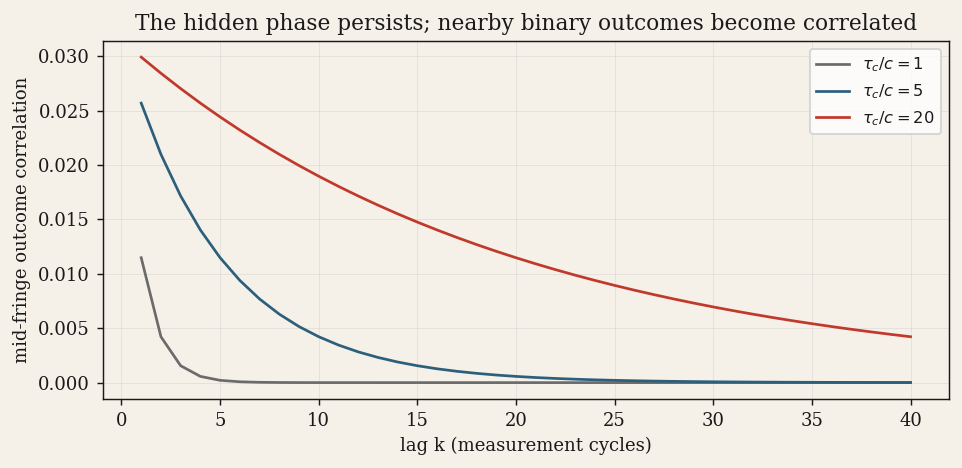

In [3]:
lags = np.arange(1, 41)
CORRELATION_TIMES = (1.0, 5.0, 20.0)
fig, ax = plt.subplots(figsize=(7.5, 3.7), facecolor=PARCH)
ax.set_facecolor(PARCH)
for tc, color in zip(CORRELATION_TIMES, [STONE, SEA, SIG]):
    correlations = rk_exact(C, s, np.exp(-lags/tc))
    ax.plot(lags, correlations, color=color, label=rf"$\tau_c/c={tc:g}$")
    print(f"tau_c/c = {tc:4.0f}: lag-one correlation {correlations[0]:.6f}")
ax.set(xlabel="lag k (measurement cycles)", ylabel="mid-fringe outcome correlation",
       title="The hidden phase persists; nearby binary outcomes become correlated")
ax.legend(fontsize=9)
fig.tight_layout(); show(fig)


> **C02 — result** — the mid-fringe lag-correlation formula is established in the ledger,
> with prior-art attribution to Wudarski and colleagues. The project's contribution concerns its
> use in detection rates and the crossover, rather than discovery of the correlator itself.

## 3. Where the useful channel changes

Information is measured in **nats per shot**: the mean log evidence against the unchanged model.
Higher information suggests a shorter record to accumulate the same evidence. That suggestion
still needs a detector and a matched false-alarm calibration before it becomes a delay result.

The extremum line uses `I_ext_exact`, the exact **one-shot Bernoulli divergence**. The mid-fringe
line uses `I_mid_gp`, the research run's **geometric-fit Gaussian spectral comparator**. Its closed
form is exact for the fitted Gaussian process; it is an approximation to the binary record's
information rate. We solve where those two quantities are equal.

These are two fixed-parameter slices, not the physical map that re-optimises interrogation time.
The mid-fringe comparator is also different from the small-signal leading-order expansion and
from a Monte Carlo HMM estimate.


pilot: comparator crossing tau_c/c = 7.17696; extremum = 1.296305e-03 nats/shot
  tau_c/c =    1: mid comparator / extremum = 0.05820
  tau_c/c =    5: mid comparator / extremum = 0.68836
  tau_c/c =   20: mid comparator / extremum = 2.37214
stress: comparator crossing tau_c/c = 4.13160; extremum = 3.196271e-04 nats/shot
  tau_c/c =    1: mid comparator / extremum = 0.10292
  tau_c/c =    5: mid comparator / extremum = 1.24660
  tau_c/c =   20: mid comparator / extremum = 4.64155


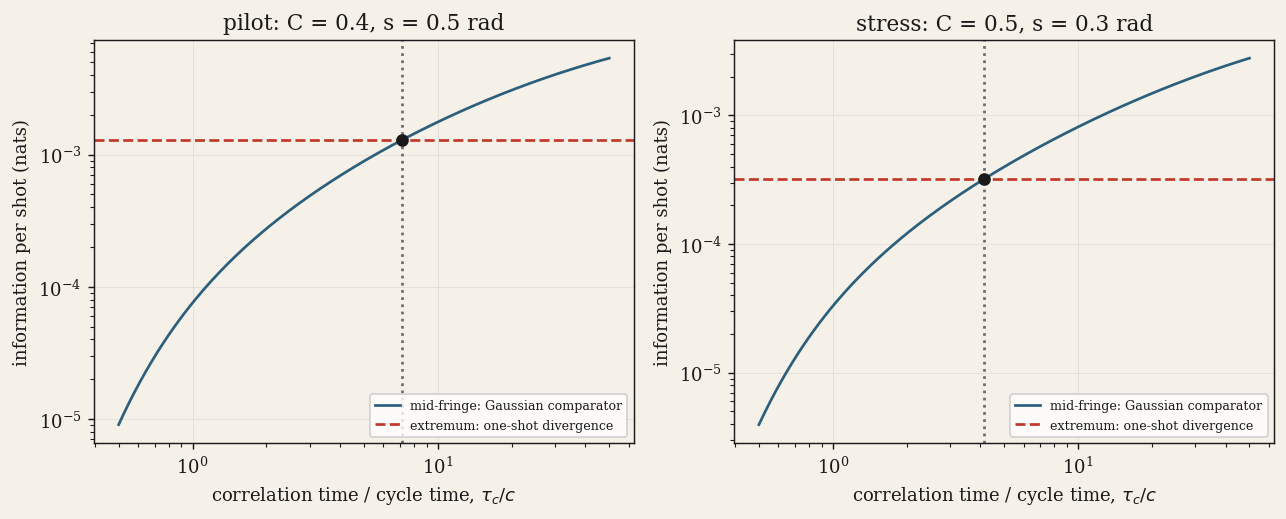

In [4]:
tc_grid = np.geomspace(0.5, 50.0, 180)
fig, axes = plt.subplots(1, 2, figsize=(10.0, 4.1), facecolor=PARCH, sharex=True)
for ax, (name, (contrast, amplitude)) in zip(axes, [("pilot", PILOT), ("stress", STRESS)]):
    ax.set_facecolor(PARCH)
    ie = I_ext_exact(contrast, amplitude)
    im = np.array([I_mid_gp(contrast, amplitude, tc) for tc in tc_grid])
    crossing = brentq(lambda tc: I_mid_gp(contrast, amplitude, tc)-ie, 0.5, 50.0)
    ax.loglog(tc_grid, im, color=SEA, label="mid-fringe: Gaussian comparator")
    ax.axhline(ie, color=SIG, ls="--", label="extremum: one-shot divergence")
    ax.axvline(crossing, color=STONE, ls=":")
    ax.scatter([crossing], [ie], color=INK, zorder=4)
    ax.set(xlabel=r"correlation time / cycle time, $\tau_c/c$",
           ylabel="information per shot (nats)",
           title=f"{name}: C = {contrast}, s = {amplitude} rad")
    ax.legend(fontsize=7, loc="lower right")
    print(f"{name}: comparator crossing tau_c/c = {crossing:.5f}; extremum = {ie:.6e} nats/shot")
    for tc in CORRELATION_TIMES:
        ratio = I_mid_gp(contrast, amplitude, tc)/ie
        print(f"  tau_c/c = {tc:4.0f}: mid comparator / extremum = {ratio:.5f}")
fig.tight_layout(); show(fig)


> **worked example** — the plotted comparison favours the extremum at short memory and
> mid-fringe at long memory at both parameter sets. The crossing moves when contrast and phase
> amplitude change. The root printed here uses a continuous solve; the published grid's first
> crossing point is a different numerical estimator.

> **C05 — result** — the ledger establishes a quantitative sequential-information crossover for
> the stated binary-link model and correlation-rate comparator. Its quoted crossover values
> are at $\bar C=0.4$; the stress-point crossing above is archived but is not part of C05.
> The stress-point calculation here is a worked example, not an extension of that claim. See the
> [claim ledger](../ledgers/status.yaml) and the
> [comparator-versus-HMM note](../notes/2026-09-04-note-08-comparator-vs-hmm-crossover.md).

> **C04 — result** — validation against the binary latent likelihood is confined to the tested
> point-sampled AR(1) cases. It does not complete roadmap F's finite-window likelihood check.

> **C24 — open** — the extremum also contains temporal information. Its additional correlation
> contribution is omitted from the flat one-shot line; the proposed numerical ceiling on that
> contribution remains unestablished. The plot is a comparison of the two named quantities.

## 4. Put the cycle back on the clock

Notebook 00 distinguished observations from wall-clock time. For a fixed protocol, divide a
per-shot information rate by its cycle time to obtain nats per unit time. Here is just the time
accounting for a specified record length.


In [5]:
N_SHOTS = 1000
tau_seconds = 1.0
dead_seconds = 0.1
cycle_seconds = tau_seconds + dead_seconds
elapsed_seconds = N_SHOTS * cycle_seconds
print(f"{N_SHOTS} interrogations: tau = {tau_seconds:.1f} s, dead time = {dead_seconds:.1f} s")
print(f"cycle = {cycle_seconds:.1f} s; record duration = {elapsed_seconds:.1f} s = {elapsed_seconds/60:.2f} min")


1000 interrogations: tau = 1.0 s, dead time = 0.1 s
cycle = 1.1 s; record duration = 1100.0 s = 18.33 min


> **worked example** — this duration prices a chosen record length; it does not assert that
> an alarm will occur within it. A physical change in interrogation time also changes contrast,
> accumulated phase variance and memory between cycles. Those must be recomputed together.

> **C08 — result** — in the $\tau$-optimised physical map, with $T_2=10t_{\rm dead}$ and
> $g\sigma_xT_2=0.5$ rad, mid-fringe wins only for $\tau_c/t_{\rm dead}\gtrsim210$ at initial
> contrast $C_0=0.4$. This is the physical threshold recorded in the
> [claim ledger](../ledgers/status.yaml), not a new calculation in this notebook.

The fixed-shot crossing near $\tau_c/c=7$ above cannot simply be converted to this threshold by
changing units. The physical map varies interrogation time, includes its effects on contrast and
integrated phase variance, and optimises each readout's information **per wall-clock time**.
Its $C_0$ is the initial contrast, whereas the earlier $C$ is contrast at one fixed interrogation.
The example cycle duration alone supplies none of those optimisations. Roadmap F's finite-window
likelihood validation remains open, as discussed above.

## 5. A channel comparison is the beginning of a policy comparison

The rate plot assumes a known parameter set and a fixed angle. A detector facing an unknown
correlation time can precommit to a schedule or choose actions from its observations. Its complete
stopping rule needs its own measured false-alarm run length, and any switching or calibration
cost must be stated.

> **C28 — result** — roadmap B found a resolved reversal for one precommitted switching schedule:
> it was worse than fixed-extremum operation at the pilot and better at the stress point under the
> stated worst-case-delay comparison. This is evidence about that schedule, not all possible ones.

> **C31 — result** — roadmap C found posterior sampling **resolvedly slower in five of six
> cells** than the independently selected, correlation-time-informed fixed endpoint. The sixth
> cell (stress, $\tau_c/c=5$) is unresolved. That reference already knows the correlation time;
> the learner must infer it. Responsiveness did not deliver a consistent detection-delay
> advantage. These measured results are separate from this notebook's rate plot.

## Try it, then explain it

1. Set `s = 0.0` only in the fringe section. What becomes of the average difference? Why does
   the mid-fringe mean by itself never tell you whether the phase has memory?
2. Inspect the printed rate ratios at short and long memory. Explain why choosing the steepest
   fringe slope is insufficient to choose the quickest detector.
3. Suppose the dark-outcome probability rises. Give two physical explanations consistent with
   that observation before reading on.

The last question opens [notebook 03 — Detection is not identification](../tutorials/03_detection_is_not_identification.ipynb).
A changed probability can establish that the old model failed while leaving the cause ambiguous.
